# SQL 기초 사용법

## Pandas

In [1]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import koreanize_matplotlib
import numpy as np
import seaborn as sns
import duckdb

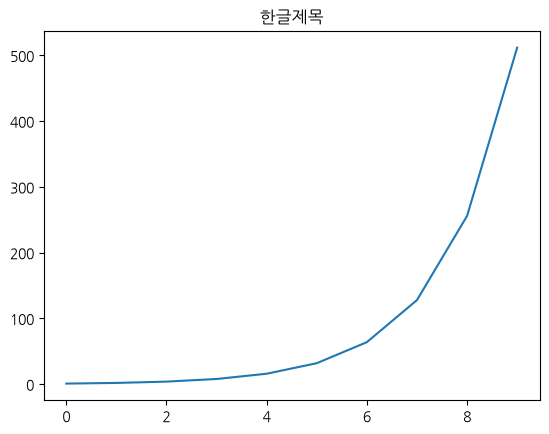

In [2]:
plt.title('한글제목')
plt.plot([2**i for i in range(10)])

In [3]:
duckdb.sql("select * from '국민연금.parquet'")

사업장명VARCHAR,사업장지번상세주소VARCHAR,법정동코드VARCHAR,시도코드VARCHAR,시군구코드VARCHAR,읍면동코드VARCHAR,사업장형태코드VARCHAR,사업장업종코드VARCHAR,사업장업종명VARCHAR,가입자수BIGINT,당월고지금액BIGINT,신규취득자수BIGINT,상실가입자수BIGINT
우성기전(주),경기도 광주시 도척면,4161033025,41,610,330,1,292201,동력식 수지 공구 제조업,4,938400,0,0
희성전자(주),서울특별시 용산구 한남동,1117013100,11,170,131,1,701201,비주거용 건물 임대업(점포 자기땅),291,175743480,0,3
(주)신영인사이트,서울특별시 중구 명동2가,1114012700,11,140,127,1,701201,비주거용 건물 임대업(점포 자기땅),0,0,0,0
디에스디엘(주),서울특별시 중구 남대문로4가,1114011700,11,140,117,1,701201,비주거용 건물 임대업(점포 자기땅),15,5884660,0,1
(주)헤럴드,서울특별시 용산구 후암동,1117010100,11,170,101,1,221200,잡지 및 정기 간행물 발행업,328,155596360,0,3
천일해운(주),서울특별시 용산구 한남동,1117013100,11,170,131,1,519113,상품 종합 도매업,8,3043360,1,1
우지기업(주),서울특별시 종로구 내자동,1111011400,11,110,114,1,749300,건축물 일반 청소업,235,51419460,20,13
디아이주식회사,서울특별시 강남구 논현동,1168010800,11,680,108,1,321000,기타 반도체 소자 제조업,61,28332540,2,2
한국관광공사,강원특별자치도 원주시 반곡동,5113011700,51,130,117,1,701201,비주거용 건물 임대업(점포 자기땅),756,370877100,5,6
뉴서울호텔(주),서울특별시 중구 태평로1가,1114010300,11,140,103,1,551001,호텔업,31,7993740,5,1


In [12]:
df = duckdb.sql("""
    select a.시도명, sum(b.당월고지금액)/sum(b.가입자수)/0.095 as 추정급여 
        from '시도.csv' a join '국민연금.parquet' b 
        on a.시도코드=b.시도코드 
        group by a.시도명
    """).df()
df

,시도명,추정급여
0,서울특별시,4.185331e+06
1,전북특별자치도,3.465247e+06
2,충청남도,4.008081e+06
3,전남광주통합특별시,3.718759e+06
4,울산광역시,4.236457e+06
5,부산광역시,3.644547e+06
6,경기도,4.056154e+06
7,충청북도,3.799362e+06
8,경상북도,3.950793e+06
9,인천광역시,3.740066e+06


<Axes: ylabel='시도명'>

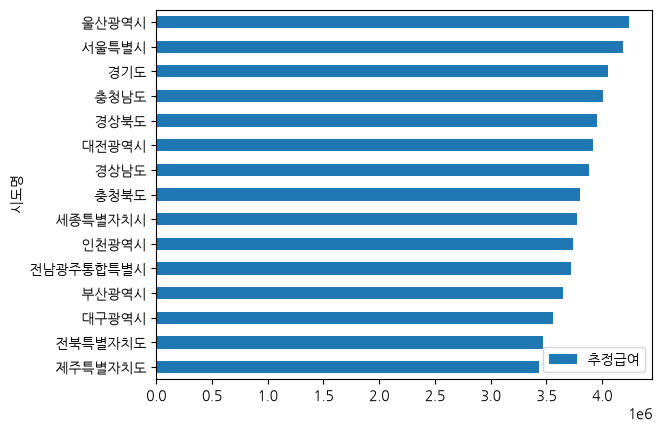

In [15]:
df1 = df.set_index('시도명').sort_values('추정급여')
df1.plot(kind='barh')